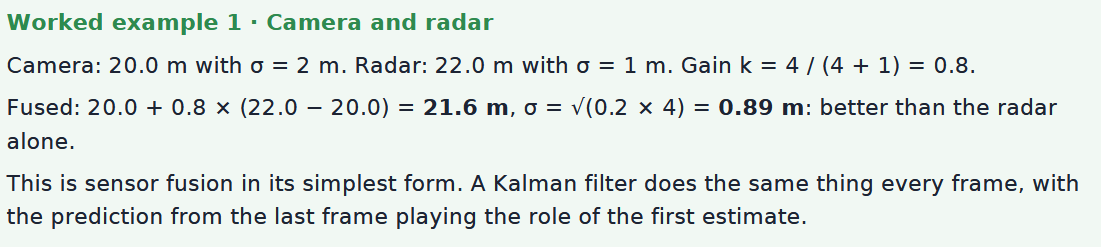

In [1]:
import numpy as np

def fuse(mu_a, var_a, mu_b, var_b):
    """Combine two independent Gaussian estimates of the same quantity."""
    k = var_a / (var_a + var_b)          # how much to trust b relative to a
    mu = mu_a + k * (mu_b - mu_a)
    var = (1 - k) * var_a                # = 1 / (1/var_a + 1/var_b)
    return mu, var, k

# camera says the car is 20.0 m away (sigma 2 m), radar says 22.0 m (sigma 1 m)
mu, var, k = fuse(20.0, 2.0**2, 22.0, 1.0**2)
print(f"fused: {mu:.2f} m, sigma {np.sqrt(var):.3f} m, weight on radar {k:.2f}")

fused: 21.60 m, sigma 0.894 m, weight on radar 0.80


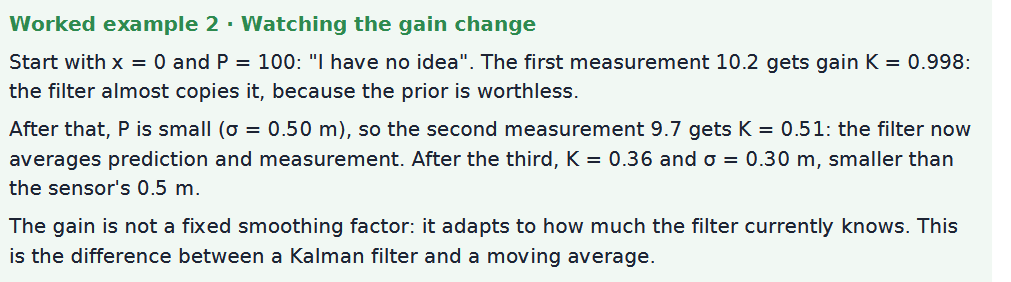

In [1]:
import numpy as np

def kf1d_step(x, P, z, q, r):
    """One cycle of a 1D Kalman filter with a constant-position model."""
    x_pred, P_pred = x, P + q            # predict: the state may have drifted by q
    K = P_pred / (P_pred + r)            # Kalman gain
    x_new = x_pred + K * (z - x_pred)    # update with the innovation z - x_pred
    P_new = (1 - K) * P_pred
    return x_new, P_new, K

x, P = 0.0, 100.0                        # start: no idea where it is (large P)
# measurements of a target at 10 m, sensor sigma 0.5 m
for z in [10.2, 9.7, 10.4]:
    x, P, K = kf1d_step(x, P, z, q=0.01, r=0.25)
    print(f"z = {z:5.1f}  ->  x = {x:6.3f}, sigma = {np.sqrt(P):.3f}, K = {K:.3f}")

z =  10.2  ->  x = 10.175, sigma = 0.499, K = 0.998
z =   9.7  ->  x =  9.933, sigma = 0.357, K = 0.509
z =  10.4  ->  x = 10.099, sigma = 0.298, K = 0.355


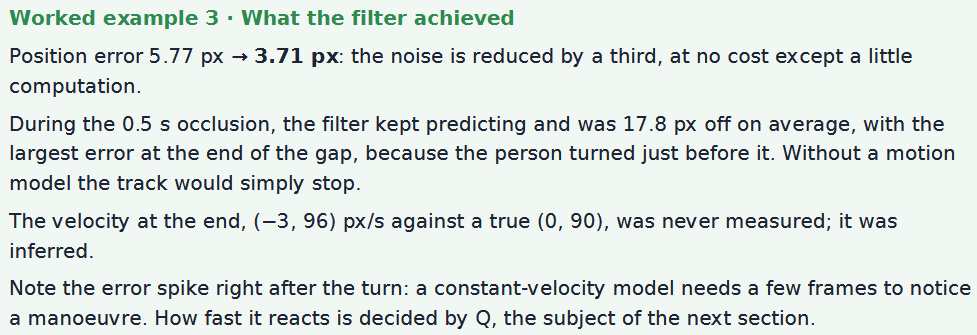

position error: raw detections 5.77 px, Kalman filter 3.71 px
during the 0.5 s occlusion (prediction only): 17.83 px
velocity at the end: (-3.0, 96.4) px/s, true (0.0, 90.0)


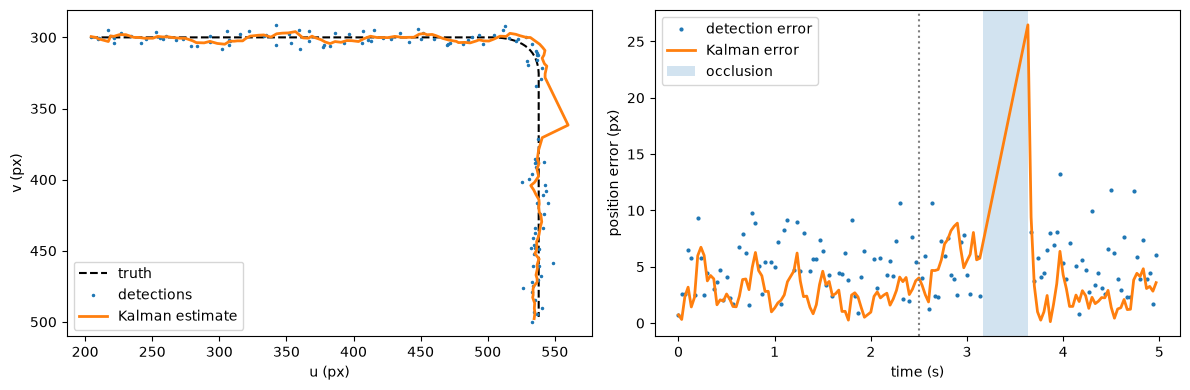

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- Kalman filter and constant-velocity model ----------
class KalmanFilter:
    """Linear Kalman filter: x' = F x + w,  z = H x + v,  w ~ N(0, Q),  v ~ N(0, R)."""
    def __init__(self, F, H, Q, R, x0, P0):
        self.F, self.H, self.Q, self.R = F, H, Q, R
        self.x, self.P = x0.astype(float), P0.astype(float)

    def predict(self):
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + self.Q
        return self.x

    def update(self, z):
        y = z - self.H @ self.x                      # innovation
        S = self.H @ self.P @ self.H.T + self.R      # innovation covariance
        K = self.P @ self.H.T @ np.linalg.inv(S)     # Kalman gain
        self.x = self.x + K @ y
        self.P = (np.eye(len(self.x)) - K @ self.H) @ self.P
        return y, S

def constant_velocity_model(dt, q, r):
    """State [x, y, vx, vy], measurement [x, y]; q: acceleration noise, r: meas. std."""
    F = np.array([[1, 0, dt, 0], [0, 1, 0, dt], [0, 0, 1, 0], [0, 0, 0, 1]], float)
    H = np.array([[1, 0, 0, 0], [0, 1, 0, 0]], float)
    G = np.array([[dt**2 / 2, 0], [0, dt**2 / 2], [dt, 0], [0, dt]])
    Q = q**2 * G @ G.T                               # white-noise acceleration
    R = r**2 * np.eye(2)
    return F, H, Q, R

# ---------- simulated pedestrian: right, then turning down ----------
rng = np.random.default_rng(0)
dt, n = 1 / 30, 150
t = np.arange(n) * dt
vx = np.where(t < 2.5, 120.0, 120.0 * np.clip(1 - (t - 2.5) / 0.6, 0, 1))   # px/s
vy = np.where(t < 2.5, 0.0, 90.0 * np.clip((t - 2.5) / 0.6, 0, 1))
truth = np.c_[200 + np.cumsum(vx) * dt, 300 + np.cumsum(vy) * dt]

meas = truth + rng.normal(0, 4.0, truth.shape)          # detector noise: 4 px
missed = rng.random(n) < 0.15                            # 15 % missed detections
missed[95:110] = True                                    # plus a short occlusion

# ---------- run the filter ----------
F, H, Q, R = constant_velocity_model(dt, q=150.0, r=4.0)
kf = KalmanFilter(F, H, Q, R, x0=np.r_[meas[0], 0, 0], P0=np.diag([16, 16, 1e4, 1e4]))
est = [kf.x[:2].copy()]
for k in range(1, n):
    kf.predict()
    if not missed[k]:
        kf.update(meas[k])
    est.append(kf.x[:2].copy())
est = np.array(est)

# ---------- results ----------
ok = ~missed
rmse_raw = np.sqrt(np.mean(np.sum((meas[ok] - truth[ok]) ** 2, axis=1)))
rmse_kf = np.sqrt(np.mean(np.sum((est[ok] - truth[ok]) ** 2, axis=1)))
gap = slice(95, 110)
gap_err = np.sqrt(np.mean(np.sum((est[gap] - truth[gap]) ** 2, axis=1)))
print(f"position error: raw detections {rmse_raw:.2f} px, Kalman filter {rmse_kf:.2f} px")
print(f"during the 0.5 s occlusion (prediction only): {gap_err:.2f} px")
print(f"velocity at the end: ({kf.x[2]:.1f}, {kf.x[3]:.1f}) px/s, true (0.0, 90.0)")

# ---------- plot: path and error over time ----------
err_raw = np.linalg.norm(meas - truth, axis=1)
err_kf = np.linalg.norm(est - truth, axis=1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(truth[:, 0], truth[:, 1], "k--", label="truth")
ax[0].plot(meas[ok, 0], meas[ok, 1], ".", ms=3, label="detections")
ax[0].plot(est[:, 0], est[:, 1], lw=2, label="Kalman estimate")
ax[0].invert_yaxis(); ax[0].set_xlabel("u (px)"); ax[0].set_ylabel("v (px)"); ax[0].legend()
ax[1].plot(t[ok], err_raw[ok], ".", ms=4, label="detection error")
ax[1].plot(t, err_kf, lw=2, label="Kalman error")
ax[1].axvspan(t[95], t[109], alpha=0.2, label="occlusion")
ax[1].axvline(2.5, ls=":", c="gray")
ax[1].set_xlabel("time (s)"); ax[1].set_ylabel("position error (px)"); ax[1].legend()
plt.tight_layout(); plt.show()